# 01 · Data exploration

What do emotional turning points look like in MELD, DailyDialog and MELD-FR, and what does that imply for modelling?

Run `bash scripts/fetch_data.sh` once, then *Run All*. Figures are saved to `reports/figures/`.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from emotionshift.data import (
    EMOTIONS,
    SHIFT_TYPES,
    add_shift_columns,
    duplicate_dialogues,
    load,
    load_meld_fr,
)
from emotionshift.data.datasets import DATA_ROOT

FIGURES = DATA_ROOT.parents[1] / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
NAMES = {"meld": "MELD", "dailydialog": "DailyDialog"}
COLORS = {"MELD": "#4C78A8", "DailyDialog": "#F58518"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

meld = add_shift_columns(load("meld"))
dd = add_shift_columns(load("dailydialog"))
both = pd.concat([meld, dd], ignore_index=True)
print(f"MELD {len(meld):,} utterances · DailyDialog {len(dd):,} utterances")

MELD 13,708 utterances · DailyDialog 102,979 utterances


## 1 · Size and label balance

In [2]:
per_dialogue = both.groupby(["dataset", "split", "dialogue_id"], sort=False).agg(
    turns=("turn", "size"), speakers=("speaker", "nunique"))
per_dialogue.groupby(["dataset", "split"], sort=False).agg(
    dialogues=("turns", "size"), utterances=("turns", "sum"),
    median_turns=("turns", "median"), mean_speakers=("speakers", "mean"))

dialogues  utterances  median_turns  mean_speakers
dataset     split                                                    
meld        train       1038        9989           9.0          2.712
            dev          114        1109          10.0          3.009
            test         280        2610           9.0          2.664
dailydialog train      11118       87170           7.0          2.000
            dev         1000        8069           8.0          2.000
            test        1000        7740           7.0          2.000

dataset,MELD,DailyDialog
emotion,,
neutral,0.472,0.828
joy,0.174,0.128
surprise,0.121,0.018
anger,0.111,0.009
sadness,0.068,0.011
disgust,0.027,0.003
fear,0.027,0.002


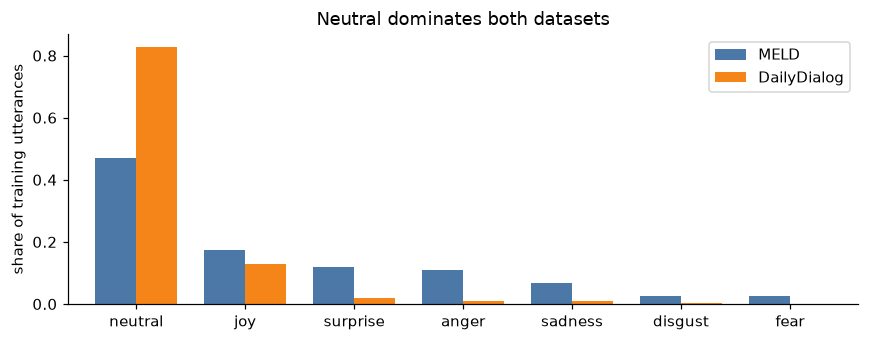

In [3]:
dist = (both[both["split"] == "train"].groupby("dataset")["emotion"]
        .value_counts(normalize=True).unstack(0).reindex(EMOTIONS))
dist = dist.rename(columns=NAMES)[["MELD", "DailyDialog"]]
ax = dist.plot.bar(figsize=(8, 3.2), width=0.75, color=COLORS)
ax.set(ylabel="share of training utterances", xlabel="", title="Neutral dominates both datasets")
ax.legend(title=None)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "label_distribution.png")
dist

## 2 · Utterance length

In [4]:
both["words"] = both["text"].str.split().str.len()
summary = both.groupby("dataset")["words"].describe(percentiles=[0.5])[["mean", "50%"]]
summary["share_up_to_3_words"] = both.groupby("dataset")["words"].apply(lambda w: (w <= 3).mean())
summary

,mean,50%,share_up_to_3_words
dataset,,,
dailydialog,11.166,9.0,0.105
meld,7.992,6.0,0.279


In [5]:
meld_len = both[both["dataset"] == "meld"]
pd.DataFrame({
    "median_words": meld_len.groupby("emotion")["words"].median(),
    "share_up_to_3_words": meld_len.groupby("emotion")["words"].apply(lambda w: (w <= 3).mean()),
}).reindex(EMOTIONS)

,median_words,share_up_to_3_words
emotion,,
neutral,6.0,0.293
joy,6.0,0.294
surprise,5.0,0.400
anger,8.0,0.195
sadness,8.5,0.160
disgust,8.0,0.183
fear,8.0,0.193


## 3 · How often, and how, emotions shift

In [6]:
eligible = both[both["stratum"] != "first"]
eligible.groupby(["dataset", "split"], sort=False)["stratum"].apply(
    lambda s: (s == "shift").mean()).rename("shift_rate").to_frame()

shift_rate
dataset     split            
meld        train       0.558
            dev         0.557
            test        0.538
dailydialog train       0.174
            dev         0.158
            test        0.180

In [7]:
types = (both[both["stratum"] == "shift"].groupby("dataset")["shift_type"]
         .value_counts(normalize=True).unstack(0).reindex(list(SHIFT_TYPES)))
types

dataset,dailydialog,meld
shift_type,,
onset,0.604,0.353
offset,0.352,0.329
valence_flip,0.010,0.085
within_negative,0.003,0.077
surprise_involved,0.032,0.157


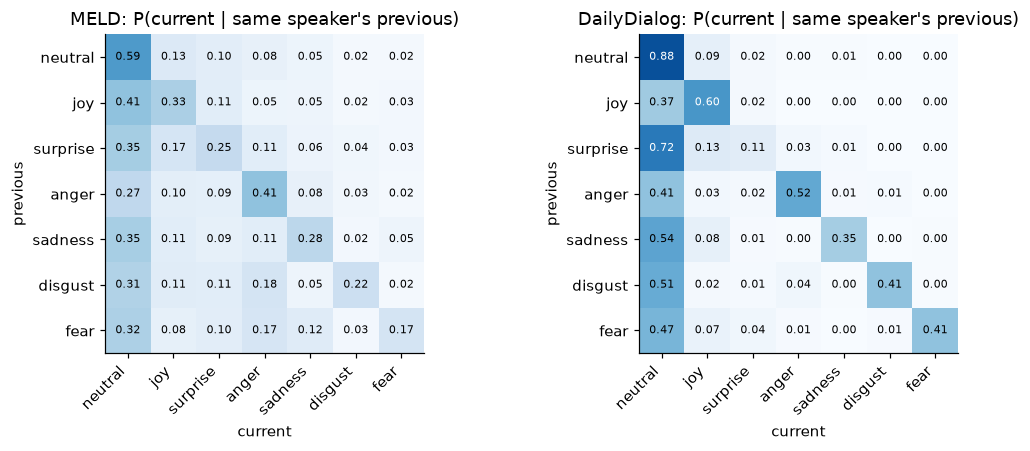

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, df) in zip(axes, [("MELD", meld), ("DailyDialog", dd)]):
    train = df[(df["split"] == "train") & (df["stratum"] != "first")]
    m = pd.crosstab(train["prev_emotion"], train["emotion"], normalize="index")
    m = m.reindex(index=EMOTIONS, columns=EMOTIONS).fillna(0)
    ax.imshow(m.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    for i in range(len(EMOTIONS)):
        for j in range(len(EMOTIONS)):
            v = m.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.6 else "black")
    ax.set_xticks(range(7), EMOTIONS, rotation=45, ha="right")
    ax.set_yticks(range(7), EMOTIONS)
    ax.set(title=f"{name}: P(current | same speaker's previous)", xlabel="current", ylabel="previous")
plt.tight_layout()
plt.savefig(FIGURES / "transition_matrices.png")

**Inertia vs contagion.** For turns where the immediately preceding utterance is by *someone else*, does the current emotion match the speaker's own previous emotion more often, or the other speaker's last emotion?

In [9]:
def inertia_vs_contagion(df):
    df = df.copy()
    df["prev_any_emotion"] = df.groupby("dialogue_id")["emotion"].shift(1)
    df["prev_any_speaker"] = df.groupby("dialogue_id")["speaker"].shift(1)
    rows = df[(df["stratum"] != "first") & (df["prev_any_speaker"] != df["speaker"])]
    return pd.Series({
        "turns": len(rows),
        "matches_own_previous": (rows["emotion"] == rows["prev_emotion"]).mean(),
        "matches_other_previous": (rows["emotion"] == rows["prev_any_emotion"]).mean(),
        "both_previous_agree": (rows["prev_emotion"] == rows["prev_any_emotion"]).mean(),
    })

pd.DataFrame({"MELD": inertia_vs_contagion(meld), "DailyDialog": inertia_vs_contagion(dd)})

,MELD,DailyDialog
turns,7018.000,76743.000
matches_own_previous,0.403,0.827
matches_other_previous,0.352,0.815
both_previous_agree,0.345,0.832


**Does a longer gap since the speaker last spoke mean more shifts?** (`turn_gap` = turns since the same speaker's previous utterance)

In [10]:
gap = eligible.assign(gap=eligible["turn_gap"].clip(upper=5).astype(int))
by_gap = gap.groupby(["dataset", "gap"])["stratum"].agg(
    shift_rate=lambda s: (s == "shift").mean(), n="size")
by_gap.unstack(0)

shift_rate                  n        
dataset dailydialog   meld dailydialog    meld
gap                                           
1               NaN  0.442         NaN  2746.0
2             0.173  0.582     76743.0  5371.0
3               NaN  0.593         NaN   637.0
4               NaN  0.650         NaN   366.0
5               NaN  0.696         NaN   684.0

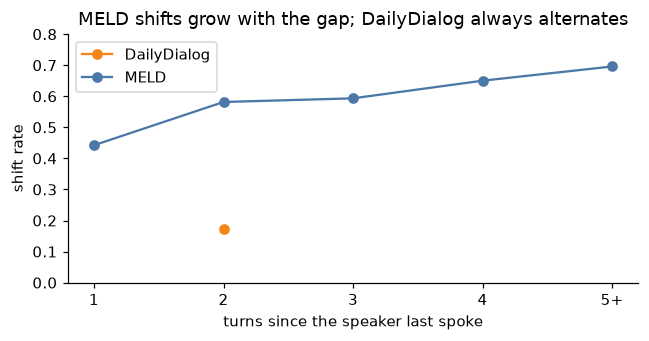

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for name, part in by_gap.groupby(level=0):
    part = part.droplevel(0)
    ax.plot(part.index, part["shift_rate"], marker="o", label=NAMES[name], color=COLORS[NAMES[name]])
ax.set_xticks([1, 2, 3, 4, 5], ["1", "2", "3", "4", "5+"])
ax.set(xlabel="turns since the speaker last spoke", ylabel="shift rate",
       title="MELD shifts grow with the gap; DailyDialog always alternates", ylim=(0, 0.8))
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "shift_rate_by_gap.png")

In [12]:
pos = eligible.assign(position=pd.cut(eligible["turn"], [0, 3, 6, 9, 14, 100],
                                       labels=["1-3", "4-6", "7-9", "10-14", "15+"]))
pos.groupby(["dataset", "position"], observed=True)["stratum"].apply(
    lambda s: (s == "shift").mean()).unstack(0)

dataset,dailydialog,meld
position,,
1-3,0.148,0.534
4-6,0.169,0.553
7-9,0.183,0.565
10-14,0.232,0.544
15+,0.215,0.600


## 4 · How much can the text alone tell us?

Many utterances are short and repeated ("Oh.", "What?"). When the *same* text carries different labels, no text-only model can get all of them right. Predicting each repeated text's majority label gives an upper bound for any text-only model on those utterances.

In [13]:
def norm(t):
    return re.sub(r"[^a-z' ]", "", t.lower()).strip()

def text_only_ceiling(df):
    df = df.assign(key=df["text"].map(norm))
    counts = df.groupby("key")["emotion"].transform("size")
    repeated = df[(counts >= 2) & (df["key"] != "")]
    best = repeated.groupby("key")["emotion"].agg(lambda s: s.value_counts().iloc[0]).sum()
    return pd.Series({"repeated_share": len(repeated) / len(df),
                      "ceiling_on_repeated": best / len(repeated),
                      "repeated_share_of_shifts": (repeated["stratum"] == "shift").sum()
                      / (df["stratum"] == "shift").sum()})

pd.DataFrame({"MELD": text_only_ceiling(meld), "DailyDialog": text_only_ceiling(dd)})

,MELD,DailyDialog
repeated_share,0.167,0.355
ceiling_on_repeated,0.698,0.908
repeated_share_of_shifts,0.156,0.416


In [14]:
top = meld.assign(key=meld["text"].map(norm))
top = top[top["key"].isin(top["key"].value_counts().head(10).index)]
pd.crosstab(top["text"].str.lower().str.strip(" .!?"), top["emotion"]).reindex(columns=EMOTIONS) \
    .assign(total=lambda t: t.sum(axis=1)).sort_values("total", ascending=False).head(10)

emotion,neutral,joy,surprise,anger,sadness,disgust,fear,total
text,,,,,,,,
hey,70,67,16,8,1,0,0,162
yeah,100,34,10,4,2,1,1,152
what,36,1,100,1,3,0,1,142
okay,106,13,4,3,0,0,1,127
hi,52,38,0,2,1,0,0,93
no,43,5,9,18,6,5,0,86
really,2,3,55,1,0,0,0,61
oh,25,3,16,0,4,0,0,48
oh my god,0,1,29,0,0,1,0,31


In [15]:
meld_e = meld[meld["stratum"] != "first"].assign(words=meld["text"].str.split().str.len())
meld_e.groupby("stratum")["words"].agg(["median", lambda w: (w <= 3).mean()]).rename(
    columns={"<lambda_0>": "share_up_to_3_words"})

,median,share_up_to_3_words
stratum,,
shift,7.0,0.266
stable,6.0,0.278


## 5 · MELD-FR: what triggers a flip?

In [16]:
fr = pd.concat([load_meld_fr(s).assign(split=s) for s in ["train", "dev", "test"]])
target_speaker = fr[fr["is_target"]].set_index("instance_id")["speaker"]
trig = fr[fr["is_trigger"]].copy()
trig["who"] = np.where(trig["is_target"], "flip utterance itself",
                       np.where(trig["speaker"].values == target_speaker.loc[trig["instance_id"]].values,
                                "same speaker, earlier", "another speaker"))
pd.crosstab(trig["split"], trig["who"], normalize="index")

who,another speaker,flip utterance itself,"same speaker, earlier"
split,,,
dev,0.617,0.241,0.142
test,0.620,0.243,0.137
train,0.612,0.225,0.163


,0 (flip itself),1,2,3,4+
split,,,,,
dev,0.241,0.646,0.073,0.020,0.020
test,0.243,0.636,0.073,0.025,0.024
train,0.225,0.485,0.108,0.074,0.109


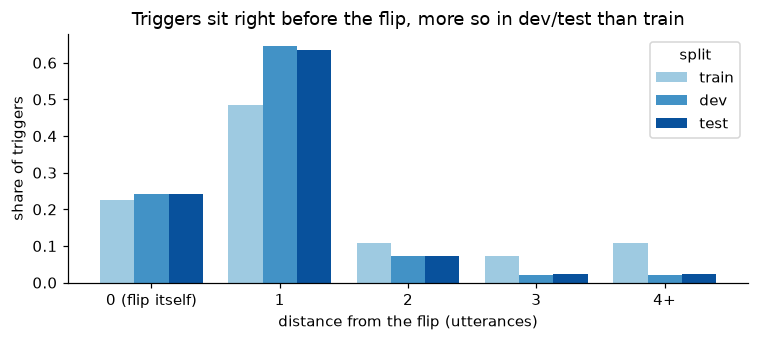

In [17]:
dist_share = pd.crosstab(trig["split"], trig["distance"].clip(upper=4), normalize="index")
dist_share.columns = ["0 (flip itself)", "1", "2", "3", "4+"]
ax = dist_share.reindex(["train", "dev", "test"]).T.plot.bar(figsize=(7, 3.2), width=0.8,
                                                            color=["#9ecae1", "#4292c6", "#08519c"])
ax.set(xlabel="distance from the flip (utterances)", ylabel="share of triggers",
       title="Triggers sit right before the flip, more so in dev/test than train")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "trigger_distance.png")
dist_share

In [18]:
per_flip = fr.groupby(["split", "instance_id"])["is_trigger"].sum()
per_flip.groupby(level=0).value_counts(normalize=True).unstack(0).head(5)

split,dev,test,train
is_trigger,,,
0,0.056,0.037,0.085
1,0.770,0.795,0.638
2,0.136,0.138,0.174
3,0.035,0.025,0.050
4,NaN,0.004,0.029


## 6 · DailyDialog train/test leakage

In [19]:
leaked = duplicate_dialogues(dd[dd["split"] == "train"], dd[dd["split"] == "test"])
test = dd[dd["split"] == "test"]
is_leaked = test["dialogue_id"].isin(leaked)
print(f"{len(leaked)} of {test['dialogue_id'].nunique()} test dialogues "
      f"({len(leaked) / test['dialogue_id'].nunique():.1%}) appear verbatim in train; "
      f"{is_leaked.sum()} test utterances")
pd.DataFrame({"leaked": test[is_leaked]["emotion"].value_counts(normalize=True),
              "clean": test[~is_leaked]["emotion"].value_counts(normalize=True)}).reindex(EMOTIONS)

109 of 1000 test dialogues (10.9%) appear verbatim in train; 773 test utterances


,leaked,clean
emotion,,
neutral,0.776,0.821
joy,0.177,0.127
surprise,0.009,0.016
anger,0.023,0.014
sadness,0.006,0.014
disgust,0.008,0.006
fear,NaN,0.002


## Findings

**1 · Label balance differs sharply.** Neutral is 47% of MELD training utterances but 83% of DailyDialog's, where fear (0.2%) and disgust (0.3%) barely exist. DailyDialog's headline metric stays micro-F1 without neutral; per-class scores there will be noisy.

**2 · MELD is short.** The median MELD utterance is 6 words and 28% have 3 words or fewer (DailyDialog: 9 words, 10.5%). Surprise is the shortest class (40% are 3 words or fewer).

**3 · Shifts are common in MELD, rare in DailyDialog, and of a different kind.** The shift rate is 54–56% in MELD against 16–18% in DailyDialog. In DailyDialog, 96% of shifts are onsets or offsets around neutral and only 1% are valence flips, against 8.5% in MELD. Valence-flip analysis is only meaningful on MELD, and cross-domain transfer (RQ5) moves between two very different regimes.

**4 · Own history beats the other speaker's last turn, but only slightly.** When someone else spoke last, a MELD speaker's emotion matches their own previous emotion 40% of the time and the other speaker's last emotion 35% of the time. That supports a per-speaker state (the speaker GRU) over simply copying the last utterance. In DailyDialog both are about 82% because almost everything is neutral.

**5 · The longer since a speaker last spoke, the more likely a shift.** MELD's shift rate rises from 44% (the speaker continues immediately) to 58% (one turn in between) and 70% (four or more). `turn_gap` should be an input to the forecast head, and it gives inertia a concrete reading: it decays as other people talk. Even back-to-back turns of one speaker shift 44% of the time, which partly reflects utterance segmentation and label noise.

**6 · Text alone is ambiguous for short utterances.** 16.7% of MELD utterances repeat a text seen elsewhere, and even predicting each repeated text's majority label caps accuracy at 69.8% on them. "Hey" is neutral 70 times and joy 67 times; "What?" is surprise 100 times and neutral 36. This is the clearest case for context, and part of the text-only ceiling.

**7 · Shift turns are not shorter than stable turns** (median 7 vs 6 words; 27% vs 28% of 3 words or fewer). A shift gap in model scores is not just a length effect.

**8 · MELD-FR triggers mostly come from another speaker, and train is annotated differently.** 62% of triggers are another speaker's utterance, 24% the flip utterance itself and 14% the same speaker earlier. Triggers one utterance back are 49% of train triggers but 64% of test triggers, triggers four or more back are 11% vs 2%, and 64% of train flips have exactly one trigger vs 80% in test. Thresholds for a trigger model must be tuned on dev, not train.

**9 · DailyDialog's leakage is not random.** 109 of 1,000 test dialogues (773 utterances) appear verbatim in train, and they are more joyful than the rest (17.7% vs 12.7% joy). The official test set overstates scores in a skewed way, so headline numbers use the de-duplicated test set.